In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/data/processed/student_encoded.csv")

# Model B (behavioral/early-factor) — exclude G1, G2 to avoid leakage

In [6]:
X_a = df.drop(columns=['G3'])   # only drop the target itself
y_a = df['G3']
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y_a, test_size=0.2, random_state=42
)
print(f"Train size: {X_train_a.shape[0]}, Test size: {X_test_a.shape[0]}")

Train size: 316, Test size: 79


# Linear Regression - model A

In [7]:
lr_a = LinearRegression()
lr_a.fit(X_train_a, y_train_a)
pred_lr_a = lr_a.predict(X_test_a)

r2_model_a_lr = r2_score(y_test_a, pred_lr_a)
mae_model_a_lr = mean_absolute_error(y_test_a, pred_lr_a)
rmse_model_a_lr = np.sqrt(mean_squared_error(y_test_a, pred_lr_a))

print("--- Model A: Linear Regression (WITH G1/G2) ---")
print(f"MAE: {mae_model_a_lr:.3f}")
print(f"RMSE: {rmse_model_a_lr:.3f}")
print(f"R² Score: {r2_model_a_lr:.3f}")


--- Model A: Linear Regression (WITH G1/G2) ---
MAE: 1.647
RMSE: 2.378
R² Score: 0.724


# Random Forest Regressor - Model A

In [8]:
rf_a = RandomForestRegressor(n_estimators=100, random_state=42)
rf_a.fit(X_train_a, y_train_a)
pred_rf_a = rf_a.predict(X_test_a)

r2_model_a_rf = r2_score(y_test_a, pred_rf_a)
mae_model_a_rf = mean_absolute_error(y_test_a, pred_rf_a)
rmse_model_a_rf = np.sqrt(mean_squared_error(y_test_a, pred_rf_a))

print("\n--- Model A: Random Forest (WITH G1/G2) ---")
print(f"MAE: {mae_model_a_rf:.3f}")
print(f"RMSE: {rmse_model_a_rf:.3f}")
print(f"R² Score: {r2_model_a_rf:.3f}")


--- Model A: Random Forest (WITH G1/G2) ---
MAE: 1.165
RMSE: 1.949
R² Score: 0.815


Model B — WITHOUT G1, G2

In [9]:
# ---------- MODEL B: Excluding G1, G2 ----------
X_b = df.drop(columns=['G1', 'G2', 'G3'])
y_b = df['G3']

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42
)

print(f"Train size: {X_train_b.shape[0]}, Test size: {X_test_b.shape[0]}")

Train size: 316, Test size: 79


# Linear Regression - Model B

In [10]:
lr_b = LinearRegression()
lr_b.fit(X_train_b, y_train_b)
pred_lr_b = lr_b.predict(X_test_b)

r2_model_b_lr = r2_score(y_test_b, pred_lr_b)
mae_model_b_lr = mean_absolute_error(y_test_b, pred_lr_b)
rmse_model_b_lr = np.sqrt(mean_squared_error(y_test_b, pred_lr_b))

print("--- Model B: Linear Regression (WITHOUT G1/G2) ---")
print(f"MAE: {mae_model_b_lr:.3f}")
print(f"RMSE: {rmse_model_b_lr:.3f}")
print(f"R² Score: {r2_model_b_lr:.3f}")


--- Model B: Linear Regression (WITHOUT G1/G2) ---
MAE: 3.395
RMSE: 4.196
R² Score: 0.141


# Random Forest - Model B

In [11]:
rf_b = RandomForestRegressor(n_estimators=100, random_state=42)
rf_b.fit(X_train_b, y_train_b)
pred_rf_b = rf_b.predict(X_test_b)

r2_model_b_rf = r2_score(y_test_b, pred_rf_b)
mae_model_b_rf = mean_absolute_error(y_test_b, pred_rf_b)
rmse_model_b_rf = np.sqrt(mean_squared_error(y_test_b, pred_rf_b))

print("\n--- Model B: Random Forest (WITHOUT G1/G2) ---")
print(f"MAE: {mae_model_b_rf:.3f}")
print(f"RMSE: {rmse_model_b_rf:.3f}")
print(f"R² Score: {r2_model_b_rf:.3f}")


--- Model B: Random Forest (WITHOUT G1/G2) ---
MAE: 3.148
RMSE: 3.935
R² Score: 0.245


comparison table

In [12]:
comparison = pd.DataFrame({
    'Model': ['Linear Reg (with G1/G2)', 'Linear Reg (without G1/G2)',
              'Random Forest (with G1/G2)', 'Random Forest (without G1/G2)'],
    'R2_Score': [r2_model_a_lr, r2_model_b_lr, r2_model_a_rf, r2_model_b_rf],
    'MAE': [mae_model_a_lr, mae_model_b_lr, mae_model_a_rf, mae_model_b_rf],
    'RMSE': [rmse_model_a_lr, rmse_model_b_lr, rmse_model_a_rf, rmse_model_b_rf]
})

print("\n--- Final Model Comparison ---")
print(comparison)

comparison.to_csv("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/outputs/tables/model_comparison_leakage.csv", index=False)


--- Final Model Comparison ---
                           Model  R2_Score       MAE      RMSE
0        Linear Reg (with G1/G2)  0.724134  1.646666  2.378370
1     Linear Reg (without G1/G2)  0.141492  3.395261  4.195681
2     Random Forest (with G1/G2)  0.814791  1.164557  1.948773
3  Random Forest (without G1/G2)  0.244710  3.147722  3.935386


# Actual vs Predicted plot

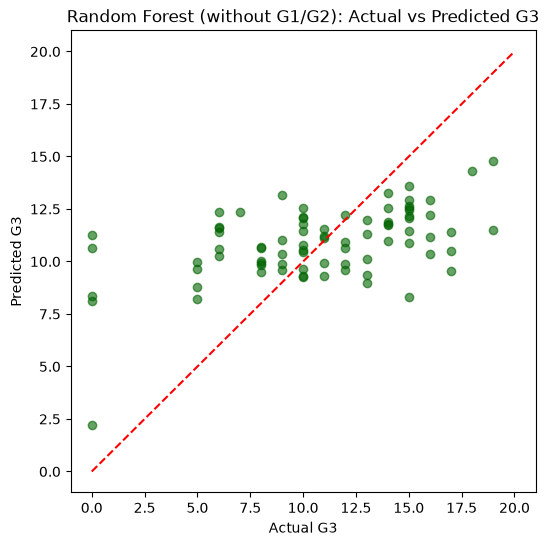

In [13]:
plt.figure(figsize=(6,6))
plt.scatter(y_test_b, pred_rf_b, alpha=0.6, color='darkgreen')
plt.plot([0,20],[0,20], color='red', linestyle='--')
plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.title("Random Forest (without G1/G2): Actual vs Predicted G3")
plt.savefig("D:/Mrunmayee/OneDrive/Desktop/student-performance-project/outputs/figures/rf_actual_vs_predicted.png")
plt.show()

In [14]:
import pickle
pickle.dump(rf_b, open("../dashboard/model_rf.pkl", "wb"))
print("Model saved for dashboard use.")

Model saved for dashboard use.
